<a href="https://colab.research.google.com/github/shagunshardia/Build-a-Media-Catalogue/blob/main/gene_drug_disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:
import pandas as pd
import networkx as nx
import sklearn
print("ready", pd.__version__, nx.__version__, sklearn.__version__)

genes = pd.read_csv("DRUG-GENE.tsv", sep="\t")
drugs = pd.read_csv("GENE-DISEASE.tsv", sep="\t")
genes.head()


ready 2.2.3 3.7 1.6.1


,gene,drug,regulatory approval,indication,interaction score
0,PPARG,L-783483,Not Approved,NaN,0.060967
1,PPARG,ISOSILYBIN A,Not Approved,NaN,0.162579
2,PPARG,CHIGLITAZAR,Not Approved,NaN,0.162579
3,PPARG,MURAGLITAZAR,Not Approved,antidiabetic,0.048774
4,PPARG,GLYBURIDE,Approved,"Hypoglycemic Agents,antidiabetic",0.015242


# Gene-Drug-Disease Network for Type 2 Diabetes

**Goal:** Build a network linking genes, drugs and type 2 diabetes, then predict missing drug-gene links with simple machine learning.

## Data
- **Gene-disease:** Open Targets Platform, "Targets associated with type 2 diabetes mellitus". File: `GENE-DISEASE.tsv`. Downloaded on 4 Nov 2026.
- **Drug-gene:** DGIdb, file `DRUG-GENE.tsv`. Downloaded on 4 Nov 2026.

## Tools
Python, pandas, NetworkX, scikit-learn, run in Google Colab.

## Decisions log
Initial DGIdb download covered only 10 genes, which is too few. Re-downloaded interactions for the top 300 genes by Open Targets globalScore.
DGIdb file version v.5.0.13, data version 2026-10
Skipped 2 comment lines at the top of the file
Dropped rows with missing gene or drug names (X rows)
Removed duplicate gene-drug pairs (X rows)
Kept genes in the top 300 by Open Targets globalScore

Assumed negatives are random gene-drug pairs with no known link, at a 5:1 ratio.
Features are the degrees, their product, and a path-length-3 count (raw and normalised), computed from the training graph only, excluding each pair’s own edge.
Models are logistic regression and random forest, compared against a degree-only baseline, with AUROC and AUPRC reported.

In [31]:
drug_gene = pd.read_csv("DRUG-GENE.tsv", sep="\t")
gene_disease = pd.read_csv("GENE-DISEASE.tsv", sep="\t")

print("drug-gene table:", drug_gene.shape)
print("gene-disease table:", gene_disease.shape)

print("unique genes in drug-gene:", drug_gene["gene"].nunique())
print("unique drugs:", drug_gene["drug"].nunique())

print(gene_disease.columns.tolist())
gene_disease.head()


drug-gene table: (361, 5)
gene-disease table: (10206, 40)
unique genes in drug-gene: 10
unique drugs: 309
['symbol', 'globalScore', 'clinicalPrecedence', 'gwasCredibleSets', 'geneBurden', 'eva', 'genomicsEngland', 'gene2Phenotype', 'uniprotLiterature', 'uniprotVariants', 'orphanet', 'clingen', 'cancerGeneCensus', 'intogen', 'evaSomatic', 'cancerBiomarkers', 'crisprScreen', 'crispr', 'reactome', 'europepmc', 'expressionAtlas', 'impc', 'maxClinicalStage', 'isInMembrane', 'isSecreted', 'hasLigand', 'hasSmallMoleculeBinder', 'hasPocket', 'mouseOrthologMaxIdentityPercentage', 'hasHighQualityChemicalProbes', 'geneticConstraint', 'mouseKoScore', 'geneEssentiality', 'hasSafetyEvent', 'isCancerDriverGene', 'paralogMaxIdentityPercentage', 'tissueSpecificity', 'tissueDistribution', 'celltypeSpecificity', 'celltypeDistribution']


,symbol,globalScore,clinicalPrecedence,gwasCredibleSets,geneBurden,eva,genomicsEngland,gene2Phenotype,uniprotLiterature,uniprotVariants,...,geneticConstraint,mouseKoScore,geneEssentiality,hasSafetyEvent,isCancerDriverGene,paralogMaxIdentityPercentage,tissueSpecificity,tissueDistribution,celltypeSpecificity,celltypeDistribution
0,KCNJ11,0.877215,0.9984847978522379,0.9580187075838174,No data,0.9145725163362355,0.865457038266544,No data,No data,No data,...,0.38756505067104907,-0.8256140889527804,0,-1,No data,-0.23718000000000003,0.70401937823764,0.14814814814814814,0.6679491935055026,0.5705882352941176
1,ABCC8,0.876412,0.9984835835668301,0.9459284174345828,No data,0.940672358134372,0.8897742701710087,No data,No data,No data,...,-0.13163516844700085,-0.26356469543168864,0,-1,No data,-0.19829250000000015,0.5377861132942992,0.37037037037037035,0.7360566039058927,0.6705882352941177
2,GCK,0.867986,0.6098787576660025,0.7165678189396232,0.9939138587279628,0.9033637394077025,0.865457038266544,No data,0.607930797611621,0.607930797611621,...,-0.19167351410572442,-0.923884157007733,0,No data,No data,0,0.4582841366724364,0.38888888888888884,0.7698653099651147,0.7588235294117647
3,PPARG,0.860975,0.9972358433076591,0.9770045049244512,0.2971312810025403,0.8475039768737684,0.9190679877429972,No data,No data,No data,...,-0.42317173377156947,-0.9815218645237994,0,-1,-1,0,0.7147489062964676,0.09259259259259256,-0.3137164879937453,0.1941176470588235
4,HNF1A,0.849801,No data,0.9382473127377635,0.9747658350770844,0.900443032435016,0.8274613634158176,No data,No data,No data,...,-0.6491920021911806,-0.9500240097977022,0,No data,-1,0,0.8466035529524749,0.8703703703703703,0.6053679432138983,0.7941176470588236


In [32]:
top = gene_disease.sort_values("globalScore", ascending=False).head(300)
print(top[["symbol", "globalScore"]].head(10))
print(len(top), "genes selected")

   symbol  globalScore
0  KCNJ11     0.877215
1   ABCC8     0.876412
2     GCK     0.867986
3   PPARG     0.860975
4   HNF1A     0.849801
5   HNF4A     0.799204
6   HNF1B     0.776802
7    INSR     0.770204
8   GLP1R     0.768689
9    WFS1     0.763916
300 genes selected


In [33]:
print(", ".join(top["symbol"]))

KCNJ11, ABCC8, GCK, PPARG, HNF1A, HNF4A, HNF1B, INSR, GLP1R, WFS1, SLC2A2, PAX4, SLC30A8, AKT2, GPD2, GIPR, NDUFS4, CDKAL1, NEUROD1, TCF7L2, IRS1, GIGYF1, MT-ND1, ENPP1, NDUFB8, HMGCR, SLC5A2, KCNQ1, DPP4, NDUFB2, MTNR1B, RFX6, FTO, NDUFB6, NDUFS3, PPARA, NDUFA10, MT-ND6, NDUFB9, NDUFA13, NDUFC2, NDUFA5, NDUFAB1, NDUFAF3, IRS2, MT-ND2, MT-ND4L, MT-ND4, MT-ND5, NDUFB4, NDUFA1, NDUFV1, NDUFA6, MT-ND3, NDUFA2, NDUFB10, NDUFV3, NDUFA11, NDUFS8, NDUFS2, NDUFB7, NDUFS1, COXFA4, NDUFS6, NDUFAF1, NDUFS5, NDUFAF2, NDUFB5, NDUFV2, NDUFB3, NDUFS7, NDUFA8, NDUFA12, NDUFC1, NDUFA9, NDUFA3, NDUFA7, COXFA4L2, NDUFB11, NDUFAF4, NDUFB1, MGAM, APOE, PDX1, AMY2A, JAZF1, KL, NR3C2, PAM, INS, UBE2E2, LPL, CTRB1, CTRB2, GAA, RASGRP1, GCKR, FGFR4, TFAP2B, SI, SLC16A11, HDAC9, MGAM2, AGTR1, RREB1, GRB14, PROX1, ABO, ADCY5, IGF2BP2, SLC22A3, DGKB, TLE1, ANKH, PNPLA3, LIPC, GLIS3, HMGA2, GRP, ADAMTS9, GPSM1, INHBB, KSR2, FBRSL1, ETV1, SLC5A1, ANGPTL4, ARAP1, BCL2L11, SLC12A8, ST6GAL1, PRC1, EYA2, SPRED2, TET2, 

In [34]:
with open("interactions.tsv") as f:
    for i in range(6):
        print(i, repr(f.readline()[:300]))

0 '# Data version: 2026-10\n'
1 '# DGIdb version: v.5.0.13\n'
2 'gene_claim_name\tgene_concept_id\tgene_name\tdrug_claim_name\tdrug_concept_id\tdrug_name\tdrug_is_approved\tdrug_is_immunotherapy\tdrug_is_antineoplastic\tinteraction_source_db_name\tinteraction_source_db_version\tinteraction_types\tinteraction_score\tdrug_specificity_score\tgene_specificity_score\tevidence_score\n'
3 'RIBONUCLEOSIDE-DIPHOSPHATE REDUCTASE M2\thgnc:10452\tRRM2\tGemcitabine prodrug\t\t\t\t\t\tTTD\t2020.06.01\t""\n'
4 'RIBONUCLEOSIDE-DIPHOSPHATE REDUCTASE M2\thgnc:10452\tRRM2\tGemcitabine\trxcui:12574\tGEMCITABINE\ttrue\tfalse\ttrue\tTTD\t2020.06.01\t""\t0.1345480877553285\t0.04216986766416245\t0.7976553829078802\t4\n'
5 'RIBONUCLEOSIDE-DIPHOSPHATE REDUCTASE M2\thgnc:10452\tRRM2\tNKP-46\t\t\t\t\t\tTTD\t2020.06.01\t""\n'


In [35]:
dg = pd.read_csv("interactions.tsv", sep="\t", skiprows=2)
print(dg.shape)
print(dg.columns.tolist())
dg.head()

(122904, 16)
['gene_claim_name', 'gene_concept_id', 'gene_name', 'drug_claim_name', 'drug_concept_id', 'drug_name', 'drug_is_approved', 'drug_is_immunotherapy', 'drug_is_antineoplastic', 'interaction_source_db_name', 'interaction_source_db_version', 'interaction_types', 'interaction_score', 'drug_specificity_score', 'gene_specificity_score', 'evidence_score']


,gene_claim_name,gene_concept_id,gene_name,drug_claim_name,drug_concept_id,drug_name,drug_is_approved,drug_is_immunotherapy,drug_is_antineoplastic,interaction_source_db_name,interaction_source_db_version,interaction_types,interaction_score,drug_specificity_score,gene_specificity_score,evidence_score
0,RIBONUCLEOSIDE-DIPHOSPHATE REDUCTASE M2,hgnc:10452,RRM2,Gemcitabine prodrug,NaN,NaN,NaN,NaN,NaN,TTD,2020.06.01,NaN,NaN,NaN,NaN,NaN
1,RIBONUCLEOSIDE-DIPHOSPHATE REDUCTASE M2,hgnc:10452,RRM2,Gemcitabine,rxcui:12574,GEMCITABINE,True,False,True,TTD,2020.06.01,NaN,0.134548,0.042170,0.797655,4.0
2,RIBONUCLEOSIDE-DIPHOSPHATE REDUCTASE M2,hgnc:10452,RRM2,NKP-46,NaN,NaN,NaN,NaN,NaN,TTD,2020.06.01,NaN,NaN,NaN,NaN,NaN
3,RIBONUCLEOSIDE-DIPHOSPHATE REDUCTASE M2,hgnc:10452,RRM2,Triapine,ncit:C2242,TRIAPINE,False,False,True,TTD,2020.06.01,NaN,1.950947,0.611463,0.797655,4.0
4,RIBONUCLEOSIDE-DIPHOSPHATE REDUCTASE M2,hgnc:10452,RRM2,CO-101,chembl:CHEMBL3039516,GEMCITABINE ELAIDATE,False,False,False,TTD,2020.06.01,NaN,2.926421,3.668778,0.797655,1.0


In [36]:
# keep only the columns we need
dg_clean = dg[["gene_name", "drug_name", "drug_is_approved"]].copy()

# drop rows with a missing gene or drug name
before = len(dg_clean)
dg_clean = dg_clean.dropna(subset=["gene_name", "drug_name"])
print("dropped for missing names:", before - len(dg_clean))

# make names consistent
dg_clean["gene_name"] = dg_clean["gene_name"].str.upper().str.strip()
dg_clean["drug_name"] = dg_clean["drug_name"].str.upper().str.strip()

# remove duplicate gene-drug pairs
before = len(dg_clean)
dg_clean = dg_clean.drop_duplicates(subset=["gene_name", "drug_name"])
print("dropped duplicates:", before - len(dg_clean))

# keep only genes in our top-300 type 2 diabetes list
top_genes = set(top["symbol"].str.upper().str.strip())
dg_t2d = dg_clean[dg_clean["gene_name"].isin(top_genes)]

print("drug-gene pairs for top genes:", len(dg_t2d))
print("genes:", dg_t2d["gene_name"].nunique(), " drugs:", dg_t2d["drug_name"].nunique())

dropped for missing names: 21795
dropped duplicates: 23070
drug-gene pairs for top genes: 3775
genes: 193  drugs: 2627


In [37]:
G = nx.Graph()
for row in dg_t2d.itertuples():
    g, d = "G:" + row.gene_name, "D:" + row.drug_name   # prefixes keep genes and drugs separate
    G.add_node(g, kind="gene")
    G.add_node(d, kind="drug")
    G.add_edge(g, d)

genes_n = [n for n, k in G.nodes(data="kind") if k == "gene"]
drugs_n = [n for n, k in G.nodes(data="kind") if k == "drug"]
print("nodes:", G.number_of_nodes(), " edges:", G.number_of_edges())
print("connected components:", nx.number_connected_components(G))
print("largest component size:", len(max(nx.connected_components(G), key=len)))
print("drugs linked to only 1 gene:", sum(1 for d in drugs_n if G.degree(d) == 1))

print("\nTop 10 gene hubs:")
for n in sorted(genes_n, key=G.degree, reverse=True)[:10]:
    print(n[2:], G.degree(n))

print("\nTop 10 multi-target drugs:")
for n in sorted(drugs_n, key=G.degree, reverse=True)[:10]:
    print(n[2:], G.degree(n))

nodes: 2820  edges: 3775
connected components: 21
largest component size: 2752
drugs linked to only 1 gene: 2032

Top 10 gene hubs:
DRD2 247
GLP1R 189
PPARG 182
PTEN 159
ADRB1 153
DRD3 127
BDNF 106
FGFR3 105
BCL2 95
PPARA 95

Top 10 multi-target drugs:
METFORMIN HYDROCHLORIDE 51
ME-344 50
NV-128 50
METFORMIN 13
OLANZAPINE 10
FLUOROURACIL 10
INSULIN, REGULAR, HUMAN 10
DEHYDRATED ALCOHOL 10
DOXORUBICIN HYDROCHLORIDE 9
REPAGLINIDE 9


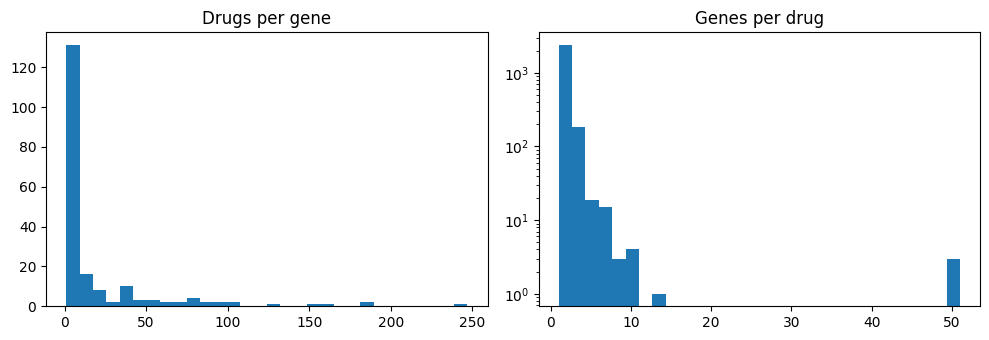

In [38]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist([G.degree(n) for n in genes_n], bins=30); ax[0].set_title("Drugs per gene")
ax[1].hist([G.degree(d) for d in drugs_n], bins=30, log=True); ax[1].set_title("Genes per drug")
plt.tight_layout(); plt.show()

21,795 DGIdb rows dropped for missing gene or drug names (limitation: unmapped drugs are excluded)
23,070 duplicate gene-drug pairs removed
193 of the top 300 genes have at least one known drug (107 have none)
Final network: 3,775 drug-gene edges, 193 genes, 2,627 drugs

In [39]:
import random
random.seed(42)          # makes the split reproducible

# list every edge as (gene, drug)
pairs = [(u, v) if G.nodes[u]["kind"] == "gene" else (v, u) for u, v in G.edges()]

# only edges where both ends have another connection can be hidden safely
eligible = [(g, d) for g, d in pairs if G.degree(g) >= 2 and G.degree(d) >= 2]
print("total edges:", len(pairs), " eligible to hide:", len(eligible))

random.shuffle(eligible)
n_test = int(0.2 * len(eligible))       # hide 20%
G_train = G.copy()
test_pos = []
for g, d in eligible:
    if len(test_pos) >= n_test:
        break
    if G_train.degree(g) >= 2 and G_train.degree(d) >= 2:   # re-check after earlier removals
        G_train.remove_edge(g, d)
        test_pos.append((g, d))

print("hidden test edges:", len(test_pos))
print("training edges:", G_train.number_of_edges())

total edges: 3775  eligible to hide: 1724
hidden test edges: 344
training edges: 3431


In [40]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score

random.seed(42)
NEG_RATIO = 5   # 5 fake pairs for every real one (closer to reality than 1:1)

# real links the model can see (training positives)
train_pos = [(u, v) if G_train.nodes[u]["kind"] == "gene" else (v, u) for u, v in G_train.edges()]

known = set(pairs)   # every known link in the FULL graph

def sample_negatives(n, avoid):
    out = set()
    while len(out) < n:
        g, d = random.choice(genes_n), random.choice(drugs_n)
        if (g, d) not in known and (g, d) not in avoid and (g, d) not in out:
            out.add((g, d))
    return list(out)

train_neg = sample_negatives(NEG_RATIO * len(train_pos), set())
test_neg = sample_negatives(NEG_RATIO * len(test_pos), set(train_neg))
print(len(train_pos), len(train_neg), len(test_pos), len(test_neg))

3431 17155 344 1720


Negatives are random pairs with no known link. They’re really “unlabelled” pairs, since a few may be real but undiscovered, which is why we call them assumed negatives in the paper.

In [41]:
def features(Gf, g, d):
    own = 1 if Gf.has_edge(g, d) else 0
    deg_g = Gf.degree(g) - own      # don't count the pair's own edge,
    deg_d = Gf.degree(d) - own      # otherwise real links would look "more connected"
    l3, l3n = 0, 0.0
    Ng = set(Gf[g])
    for g2 in Gf[d]:                # paths of length 3: gene - drug2 - gene2 - drug
        if g2 == g:
            continue
        for d2 in Ng & set(Gf[g2]):
            if d2 == d:
                continue
            l3 += 1
            l3n += 1 / np.sqrt(Gf.degree(d2) * Gf.degree(g2))
    return [deg_g, deg_d, deg_g * deg_d, l3, l3n]

def build(Gf, pos, neg):
    X = np.array([features(Gf, g, d) for g, d in pos + neg], dtype=float)
    return np.log1p(X), np.array([1] * len(pos) + [0] * len(neg))

X_train, y_train = build(G_train, train_pos, train_neg)
X_test, y_test = build(G_train, test_pos, test_neg)
print(X_train.shape, X_test.shape)

(20586, 5) (2064, 5)


Two details matter here. Both cells use G_train, never G, so there’s no leakage. And the degree features exclude the pair’s own edge, so training positives are scored the same way as hidden test edges. This cell may take a minute or two.

In [42]:
def evaluate(name, model, idx):
    model.fit(X_train[:, idx], y_train)
    p = model.predict_proba(X_test[:, idx])[:, 1]
    print(f"{name:26s} AUROC={roc_auc_score(y_test, p):.3f}  AUPRC={average_precision_score(y_test, p):.3f}")
    return p

lr = lambda: make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
print("random-guess AUPRC:", round(y_test.mean(), 3))
evaluate("degree product only", lr(), [2])
evaluate("path-3 features only", lr(), [3, 4])
evaluate("all features (LR)", lr(), [0, 1, 2, 3, 4])
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1)
p_rf = evaluate("all features (RF)", rf, [0, 1, 2, 3, 4])

random-guess AUPRC: 0.167
degree product only        AUROC=0.107  AUPRC=0.095
path-3 features only       AUROC=0.844  AUPRC=0.759
all features (LR)          AUROC=0.942  AUPRC=0.843
all features (RF)          AUROC=0.782  AUPRC=0.671


What to look for

The random-guess AUPRC (about 0.17 with a 5:1 ratio) is the floor.
The “degree product only” row is your hub-bias baseline. It probably scores well, because random negatives are easy and hub genes and drugs are connected to everything. A good result means the path-3 and combined models beat that row, not just beat random.
If the combined models barely improve on degree alone, report that honestly. It’s a legitimate finding, and it matches the warning in the review paper.

degree product only        AUROC=0.107  AUPRC=0.095
path-3 only                AUROC=0.844  AUPRC=0.759


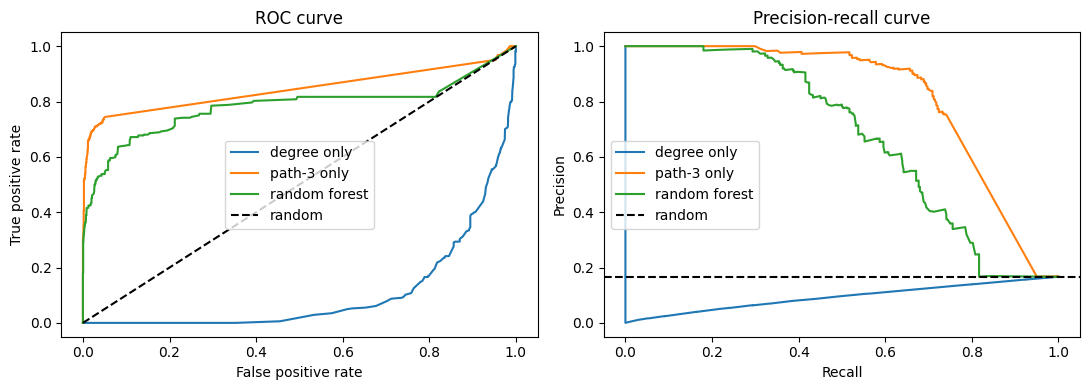

degree only {50: np.float64(0.0), 100: np.float64(0.0), 200: np.float64(0.0)}
path-3 only {50: np.float64(1.0), 100: np.float64(1.0), 200: np.float64(0.95)}
random forest {50: np.float64(1.0), 100: np.float64(0.99), 200: np.float64(0.8)}


In [43]:
from sklearn.metrics import roc_curve, precision_recall_curve

p_deg = evaluate("degree product only", lr(), [2])
p_l3 = evaluate("path-3 only", lr(), [3, 4])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, p in [("degree only", p_deg), ("path-3 only", p_l3), ("random forest", p_rf)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=name)
    ax[1].plot(rc, pr, label=name)
ax[0].plot([0, 1], [0, 1], "k--", label="random")
ax[0].set_title("ROC curve"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[1].axhline(y_test.mean(), color="k", ls="--", label="random")
ax[1].set_title("Precision-recall curve"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.show()

# of the k highest-scored test pairs, how many are real hidden links?
for name, p in [("degree only", p_deg), ("path-3 only", p_l3), ("random forest", p_rf)]:
    order = np.argsort(-p)
    print(name, {k: round(y_test[order[:k]].mean(), 2) for k in (50, 100, 200)})

How to read the results

The model score is for ranking only. Because of the 5:1 negative ratio it isn’t a real probability.
Expect the top pairs to involve your hub genes and well-connected drugs. That’s the hub bias again, so compare with the degree-only model rather than assuming the top hits are biologically special.
Treat the list as hypotheses. Search PubMed for each top gene-drug pair, because some may already be reported even if DGIdb doesn’t list them. That literature check is your validation step.
The rankings come from a model trained on the training graph and applied to the full graph, so the full graph’s extra edges are a small shift from training conditions. Mention that as a limitation.

In [44]:
gi = {g: i for i, g in enumerate(genes_n)}
di = {d: i for i, d in enumerate(drugs_n)}
A = np.zeros((len(genes_n), len(drugs_n)))
for g, d in pairs:
    A[gi[g], di[d]] = 1

deg_g, deg_d = A.sum(1), A.sum(0)
wg, wd = 1 / np.sqrt(np.maximum(deg_g, 1)), 1 / np.sqrt(np.maximum(deg_d, 1))
L3 = A @ (A.T @ A)                    # paths of length 3
L3n = (A * wd) @ (A.T * wg) @ A       # normalised version

DG = np.repeat(deg_g[:, None], A.shape[1], axis=1)
DD = np.repeat(deg_d[None, :], A.shape[0], axis=0)
F = np.log1p(np.stack([DG, DD, DG * DD, L3, L3n], axis=-1).reshape(-1, 5))

score = rf.predict_proba(F)[:, 1].reshape(A.shape)
score[A == 1] = -1                    # drop pairs that are already known

appr = dg_t2d.drop_duplicates("drug_name").set_index("drug_name")["drug_is_approved"]
gscore = top.assign(sym=top["symbol"].str.upper().str.strip()).drop_duplicates("sym").set_index("sym")["globalScore"]

best = np.dstack(np.unravel_index(np.argsort(-score, axis=None)[:30], score.shape))[0]
rows = [(genes_n[i][2:], drugs_n[j][2:], round(score[i, j], 3), appr.get(drugs_n[j][2:]),
         round(gscore.get(genes_n[i][2:], np.nan), 3)) for i, j in best]
pd.DataFrame(rows, columns=["gene", "drug", "model_score", "approved", "T2D_score"])

,gene,drug,model_score,approved,T2D_score
0,P2RY12,CHEMBL:CHEMBL578944,0.995,False,0.458
1,P2RY12,CHLORHEXIDINE GLUCONATE,0.995,True,0.458
2,P2RY12,PIRAGLIATIN,0.995,False,0.458
3,P2RY12,RO-281675,0.995,False,0.458
4,P2RY12,ASTRESSIN,0.995,False,0.458
5,P2RY12,K31440,0.995,False,0.458
6,P2RY12,ASTRESSIN 2B,0.995,False,0.458
7,P2RY12,ANTISAUVAGINE,0.995,False,0.458
8,P2RY12,SAN-300,0.995,False,0.458
9,P2RY12,KERACYANIN CATION,0.995,False,0.458


In [46]:

import pandas as pd
import numpy as np

# Randomly generated dataset of parking violations-
# Define the number of rows
num_rows = 1000000

states = ["NY", "NJ", "CA", "TX"]
violations = ["Double Parking", "Expired Meter", "No Parking",
              "Fire Hydrant", "Bus Stop"]
vehicle_types = ["SUBN", "SDN"]

# Create a date range
start_date = "2022-01-01"
end_date = "2022-12-31"
dates = pd.date_range(start=start_date, end=end_date, freq='D')

# Generate random data
data = {
    "Registration State": np.random.choice(states, size=num_rows),
    "Violation Description": np.random.choice(violations, size=num_rows),
    "Vehicle Body Type": np.random.choice(vehicle_types, size=num_rows),
    "Issue Date": np.random.choice(dates, size=num_rows),
    "Ticket Number": np.random.randint(1000000000, 9999999999, size=num_rows)
}

# Create a DataFrame
df = pd.DataFrame(data)

# Which parking violation is most commonly committed by vehicles from various U.S states?

(df[["Registration State", "Violation Description"]]  # get only these two columns
 .value_counts()  # get the count of offences per state and per type of offence
 .groupby("Registration State")  # group by state
 .head(1)  # get the first row in each group (the type of offence with the largest count)
 .sort_index()  # sort by state name
 .reset_index()
)

,Registration State,Violation Description,count
0,CA,Fire Hydrant,50314
1,NJ,Bus Stop,50118
2,NY,Double Parking,50515
3,TX,Bus Stop,50269
